# Assignment 1 – Parkinson's Disease Classification
**Name:** Juan Antonio Sainz Galvez
**Course:** CSCN8000 – Artificial Intelligence Algorithms and Mathematics
**Assignment:** Assignment 1

**Problem statement:** Given the symptoms exhibited in a patient (voice-recording measurements) and a database of
anonymized patient records, predict whether the patient is likely to have Parkinson's disease. A model like this could
be used by a program to give decision support to medical professionals.

**Dataset:** UCI Machine Learning Repository – *Parkinson's Disease Classification* (id 470)
https://archive.ics.uci.edu/dataset/470/parkinson+s+disease+classification

## Setup and configuration
All the libraries used in this notebook, the random seed, and the automatic download of the dataset from the UCI
repository. Running this notebook top to bottom reproduces every result.

In [1]:
import io
import subprocess
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)

RANDOM_STATE = 42
DATA_DIR = Path("data")
DATA_FILE = DATA_DIR / "pd_speech_features.csv"
DATA_URL = "https://archive.ics.uci.edu/static/public/470/parkinson+s+disease+classification.zip"

pd.set_option("display.max_columns", 20)
sns.set_theme(style="whitegrid")

In [2]:
# The UCI zip contains the data as a RAR archive (pd_speech_features.rar).
# Windows 10/11 includes 'tar' (libarchive), which can extract RAR files, so no extra software is needed.
DATA_DIR.mkdir(exist_ok=True)
if not DATA_FILE.exists():
    print("Downloading dataset from UCI ...")
    with urllib.request.urlopen(DATA_URL) as response:
        zip_bytes = response.read()
    with zipfile.ZipFile(io.BytesIO(zip_bytes)) as zf:
        zf.extractall(DATA_DIR)
        print("Files in the UCI zip:", zf.namelist())
    for rar in DATA_DIR.glob("*.rar"):
        subprocess.run(["tar", "-xf", rar.name], cwd=DATA_DIR, check=True)
    csv_files = list(DATA_DIR.rglob("*.csv"))
    if not csv_files:
        raise FileNotFoundError("No CSV found after extracting the UCI files.")
    if csv_files[0] != DATA_FILE:
        csv_files[0].replace(DATA_FILE)
print("Dataset file:", DATA_FILE.resolve())

Files in the UCI zip: ['pd_speech_features.rar']
Dataset file: C:\AI\CSCN8000\Assignment1_Parkinsons\data\pd_speech_features.csv


In [3]:
# The original CSV has an extra first row that only groups the features by type
# (Baseline Features, MFCC, Wavelet ...). If 'id' is not a column name, the real header is the second row.
df = pd.read_csv(DATA_FILE)
if "id" not in df.columns:
    df = pd.read_csv(DATA_FILE, header=1)
assert {"id", "class"} <= set(df.columns), f"Unexpected columns: {list(df.columns[:5])} ..."
df.head()

,id,gender,PPE,DFA,RPDE,numPulses,numPeriodsPulses,meanPeriodPulses,stdDevPeriodPulses,locPctJitter,...,tqwt_kurtosisValue_dec_28,tqwt_kurtosisValue_dec_29,tqwt_kurtosisValue_dec_30,tqwt_kurtosisValue_dec_31,tqwt_kurtosisValue_dec_32,tqwt_kurtosisValue_dec_33,tqwt_kurtosisValue_dec_34,tqwt_kurtosisValue_dec_35,tqwt_kurtosisValue_dec_36,class
0,0,1,0.85247,0.71826,0.57227,240,239,0.008064,0.000087,0.00218,...,1.5620,2.6445,3.8686,4.2105,5.1221,4.4625,2.6202,3.0004,18.9405,1
1,0,1,0.76686,0.69481,0.53966,234,233,0.008258,0.000073,0.00195,...,1.5589,3.6107,23.5155,14.1962,11.0261,9.5082,6.5245,6.3431,45.1780,1
2,0,1,0.85083,0.67604,0.58982,232,231,0.008340,0.000060,0.00176,...,1.5643,2.3308,9.4959,10.7458,11.0177,4.8066,2.9199,3.1495,4.7666,1
3,1,0,0.41121,0.79672,0.59257,178,177,0.010858,0.000183,0.00419,...,3.7805,3.5664,5.2558,14.0403,4.2235,4.6857,4.8460,6.2650,4.0603,1
4,1,0,0.32790,0.79782,0.53028,236,235,0.008162,0.002669,0.00535,...,6.1727,5.8416,6.0805,5.7621,7.7817,11.6891,8.2103,5.0559,6.1164,1


## Question 1 – Data Analysis, Data Preprocessing and Data Standardization
### i. Data Analysis

In [4]:
print("Rows (voice recordings):", df.shape[0])
print("Columns:", df.shape[1])
print("Unique patients (id):", df["id"].nunique())
print("Recordings per patient:", df.groupby("id").size().value_counts().to_dict())
print("Missing values in the whole table:", int(df.isna().sum().sum()))
print("Duplicated rows:", int(df.duplicated().sum()))
print("Column data types:", df.dtypes.value_counts().to_dict())

Rows (voice recordings): 756
Columns: 755
Unique patients (id): 252
Recordings per patient: {3: 252}
Missing values in the whole table: 0
Duplicated rows: 1
Column data types: {dtype('float64'): 749, dtype('int64'): 6}


In [5]:
patients = df.groupby("id").agg(cls=("class", "first"), gender=("gender", "first"))
summary = pd.DataFrame({
    "recordings": df["class"].value_counts(),
    "patients": patients["cls"].value_counts(),
})
summary.index = summary.index.map({0: "0 = Healthy", 1: "1 = Parkinson's"})
summary["% of recordings"] = (summary["recordings"] / summary["recordings"].sum() * 100).round(1)
summary

,recordings,patients,% of recordings
1 = Parkinson's,564,188,74.6
0 = Healthy,192,64,25.4


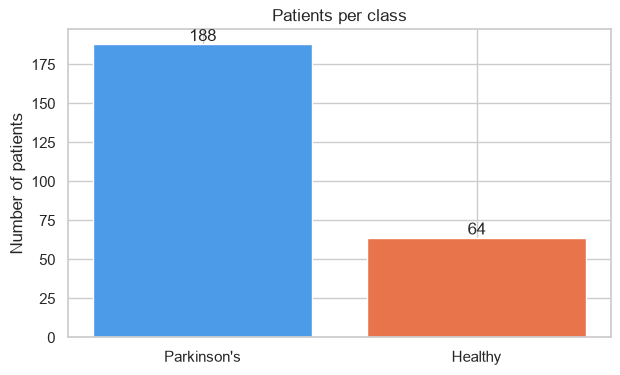

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
counts = patients["cls"].map({0: "Healthy", 1: "Parkinson's"}).value_counts()
ax.bar(counts.index, counts.values, color=["#4C9BE8", "#E8744C"])
for i, v in enumerate(counts.values):
    ax.text(i, v + 2, str(v), ha="center")
ax.set_title("Patients per class")
ax.set_ylabel("Number of patients")
plt.show()

In [7]:
# A first look at a few baseline voice features (jitter, shimmer and harmonicity measures)
baseline = ["PPE", "DFA", "RPDE", "numPulses", "meanPeriodPulses", "locPctJitter", "locShimmer", "meanHarmToNoiseHarmonicity"]
baseline = [c for c in baseline if c in df.columns]
df[baseline + ["class"]].groupby("class").mean().T.rename(columns={0: "Healthy (mean)", 1: "Parkinson's (mean)"})

class,Healthy (mean),Parkinson's (mean)
PPE,0.767434,0.739084
DFA,0.663866,0.712856
RPDE,0.430807,0.508888
numPulses,372.244792,307.539007
meanPeriodPulses,0.005699,0.006585
locPctJitter,0.001405,0.002637
locShimmer,0.055573,0.071524
meanHarmToNoiseHarmonicity,20.874354,18.173770


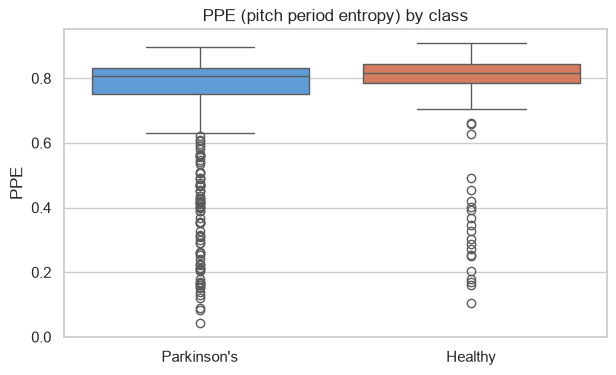

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=df, x=df["class"].map({0: "Healthy", 1: "Parkinson's"}), y="PPE", ax=ax,
            hue=df["class"].map({0: "Healthy", 1: "Parkinson's"}), palette=["#4C9BE8", "#E8744C"], legend=False)
ax.set_title("PPE (pitch period entropy) by class")
ax.set_xlabel("")
plt.show()

**Findings of the analysis**
- Each patient appears **3 times** (three voice recordings per person). This matters for the train/test split:
  if the same person is in training and in testing, the model "recognizes the person" and the accuracy looks better
  than it really is (data leakage).
- There are about **750 numeric features** per recording, measured on very different scales (some near 0.001,
  others in the thousands), so the distance-based models (KNN, SVM) need standardized data.
- The classes are **imbalanced** (around three Parkinson's patients for every healthy one), so besides accuracy we
  also look at precision, recall and F1 per class.

### ii. Data Preprocessing

In [9]:
df = df.drop_duplicates()

# Target, features and patient groups
y = df["class"].astype(int)
groups = df["id"]
X = df.drop(columns=["id", "class"])   # 'id' is only an identifier, never a feature

# Make sure every feature is numeric and there is nothing missing
X = X.apply(pd.to_numeric, errors="coerce")
print("Missing values after conversion:", int(X.isna().sum().sum()))
X = X.fillna(X.median())

# Remove constant columns (they carry no information)
constant_cols = X.columns[X.nunique() <= 1]
X = X.drop(columns=constant_cols)
print("Constant columns removed:", len(constant_cols))
print("Final feature matrix:", X.shape)

Missing values after conversion: 0
Constant columns removed: 0
Final feature matrix: (755, 753)


### iii. Data Standardization
`StandardScaler` transforms every feature to mean 0 and standard deviation 1: $z = \frac{x - \mu}{\sigma}$.

The scaler is **fitted only on the training data** and then applied to the test data. It is placed inside a
scikit-learn `Pipeline` together with each model, so the test set never influences the scaling (no leakage).
The effect of the standardization is shown right after the split in Question 2.

## Question 2 – Use 80% of samples as training data
We use `GroupShuffleSplit` with `test_size=0.2`, grouping by patient `id`, so **all three recordings of a patient go
to the same side** (train or test). This gives ~80% of the samples for training and tests the models on patients they
have never seen, which is how the system would be used with a new patient.

In [10]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
ids_train, ids_test = groups.iloc[train_idx], groups.iloc[test_idx]

print(f"Training samples: {len(X_train)} ({len(X_train)/len(X):.1%})  -  patients: {ids_train.nunique()}")
print(f"Test samples:     {len(X_test)} ({len(X_test)/len(X):.1%})  -  patients: {ids_test.nunique()}")
print("Patients in both sets:", len(set(ids_train) & set(ids_test)))
print("Parkinson's share  train: {:.1%}  test: {:.1%}".format(y_train.mean(), y_test.mean()))

Training samples: 602 (79.7%)  -  patients: 201
Test samples:     153 (20.3%)  -  patients: 51
Patients in both sets: 0
Parkinson's share  train: 75.1%  test: 72.5%


In [11]:
# Standardization check (fitted on training data only)
scaler_demo = StandardScaler().fit(X_train)
X_train_std = pd.DataFrame(scaler_demo.transform(X_train), columns=X.columns)
pd.DataFrame({
    "mean before": X_train[baseline].mean(),
    "std before": X_train[baseline].std(),
    "mean after": X_train_std[baseline].mean().round(3),
    "std after": X_train_std[baseline].std().round(3),
})

,mean before,std before,mean after,std after
PPE,0.749737,0.164722,0.0,1.001
DFA,0.700554,0.067660,0.0,1.001
RPDE,0.489998,0.143404,-0.0,1.001
numPulses,320.413621,98.857096,-0.0,1.001
meanPeriodPulses,0.006432,0.001857,-0.0,1.001
locPctJitter,0.002406,0.002831,-0.0,1.001
locShimmer,0.067789,0.043510,0.0,1.001
meanHarmToNoiseHarmonicity,18.780555,5.597397,0.0,1.001


## Question 3 – Model Training
Each model is a `Pipeline`: **StandardScaler → classifier**.
- **K-Nearest Neighbors (KNN):** classifies a recording by the majority class of its 5 closest recordings.
- **Random Forest:** many decision trees trained on random subsets; the final answer is the vote of all trees.
- **Support Vector Machine (SVM):** finds the boundary with the widest margin between classes (RBF kernel).
- **Decision Tree:** a single tree of yes/no questions on the features.

In [12]:
models = {
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "SVM": SVC(kernel="rbf", C=1.0, gamma="scale", random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
}

pipelines = {}
for name, model in models.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("model", model)])
    pipe.fit(X_train, y_train)
    pipelines[name] = pipe
    print(f"{name:14s} trained")

KNN            trained


Random Forest  trained
SVM            trained


Decision Tree  trained


## Question 4 – Predict the class (Parkinson's disease) on the test data for all the models

In [13]:
predictions = {name: pipe.predict(X_test) for name, pipe in pipelines.items()}

pred_table = pd.DataFrame({"patient_id": ids_test.values, "actual_class": y_test.values})
for name, pred in predictions.items():
    pred_table[f"{name} prediction"] = pred
pred_table.head(10)

,patient_id,actual_class,KNN prediction,Random Forest prediction,SVM prediction,Decision Tree prediction
0,6,1,1,1,1,0
1,6,1,1,1,1,1
2,6,1,1,1,1,1
3,9,1,1,1,1,1
4,9,1,0,1,1,1
5,9,1,1,1,1,1
6,10,1,1,1,1,1
7,10,1,1,1,1,1
8,10,1,1,1,1,1
9,15,1,1,1,1,1


## Question 5 – Predictive system for a new sample
`predict_parkinsons()` receives the voice measurements of one new recording and returns the diagnosis of every model.
To verify it, we use one recording from the **test set** (a patient the models never saw during training) and compare
the predictions with the real diagnosis.

In [14]:
LABELS = {0: "Healthy", 1: "Parkinson's disease"}

def predict_parkinsons(sample):
    """sample: one row of voice features (Series, dict or list in the same column order as X)."""
    sample_df = pd.DataFrame([sample], columns=X.columns)
    return {name: LABELS[int(pipe.predict(sample_df)[0])] for name, pipe in pipelines.items()}

# New sample: one Parkinson's recording and one healthy recording taken from unseen patients
for label in (1, 0):
    pos = int(np.where(y_test.values == label)[0][0])
    new_sample = X_test.iloc[pos]
    print(f"Patient id {ids_test.iloc[pos]} - real diagnosis: {LABELS[label]}")
    for model_name, diagnosis in predict_parkinsons(new_sample).items():
        print(f"   {model_name:14s} -> {diagnosis}")
    print()

Patient id 6 - real diagnosis: Parkinson's disease
   KNN            -> Parkinson's disease
   Random Forest  -> Parkinson's disease
   SVM            -> Parkinson's disease
   Decision Tree  -> Healthy

Patient id 24 - real diagnosis: Healthy
   KNN            -> Healthy
   Random Forest  -> Parkinson's disease
   SVM            -> Parkinson's disease
   Decision Tree  -> Parkinson's disease



## Question 6 – Accuracy, best model, confusion matrices and classification reports

In [15]:
results = pd.DataFrame({
    "Model": list(predictions),
    "Accuracy": [accuracy_score(y_test, p) for p in predictions.values()],
}).sort_values("Accuracy", ascending=False).reset_index(drop=True)
results["Accuracy %"] = (results["Accuracy"] * 100).round(2)
best_model = results.loc[0, "Model"]
print(f"Best model (highest accuracy): {best_model} with {results.loc[0, 'Accuracy %']}%")
results

Best model (highest accuracy): Random Forest with 83.01%


,Model,Accuracy,Accuracy %
0,Random Forest,0.830065,83.01
1,SVM,0.810458,81.05
2,KNN,0.797386,79.74
3,Decision Tree,0.764706,76.47


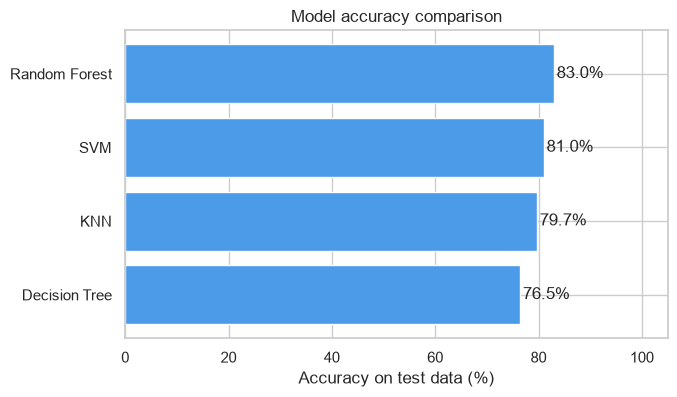

In [16]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(results["Model"][::-1], results["Accuracy %"][::-1], color="#4C9BE8")
for i, v in enumerate(results["Accuracy %"][::-1]):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center")
ax.set_xlim(0, 105)
ax.set_xlabel("Accuracy on test data (%)")
ax.set_title("Model accuracy comparison")
plt.show()

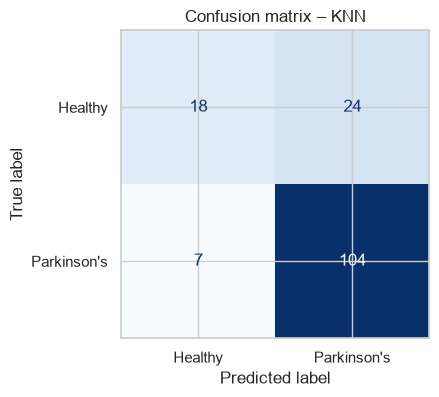

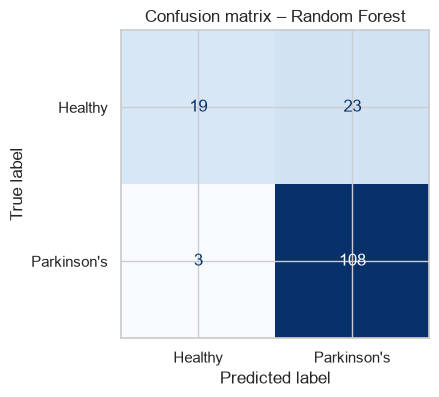

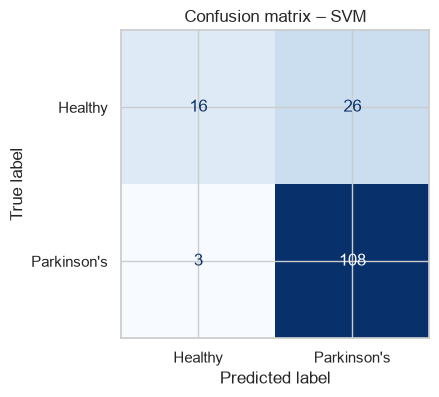

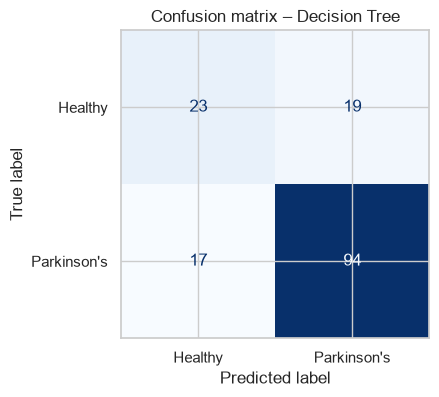

In [17]:
for name, pred in predictions.items():
    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Healthy", "Parkinson's"]).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"Confusion matrix – {name}")
    plt.show()

In [18]:
for name, pred in predictions.items():
    print(f"===== {name} =====")
    print(classification_report(y_test, pred, target_names=["Healthy", "Parkinson's"], digits=3))

===== KNN =====
              precision    recall  f1-score   support

     Healthy      0.720     0.429     0.537        42
 Parkinson's      0.812     0.937     0.870       111

    accuracy                          0.797       153
   macro avg      0.766     0.683     0.704       153
weighted avg      0.787     0.797     0.779       153

===== Random Forest =====
              precision    recall  f1-score   support

     Healthy      0.864     0.452     0.594        42
 Parkinson's      0.824     0.973     0.893       111

    accuracy                          0.830       153
   macro avg      0.844     0.713     0.743       153
weighted avg      0.835     0.830     0.811       153

===== SVM =====
              precision    recall  f1-score   support

     Healthy      0.842     0.381     0.525        42
 Parkinson's      0.806     0.973     0.882       111

    accuracy                          0.810       153
   macro avg      0.824     0.677     0.703       153
weighted avg    

In [19]:
rows = []
for name, pred in predictions.items():
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rep = classification_report(y_test, pred, output_dict=True)
    rows.append({
        "Model": name,
        "Accuracy %": round(accuracy_score(y_test, pred) * 100, 2),
        "Parkinson's found (TP)": tp, "Parkinson's missed (FN)": fn,
        "Healthy correct (TN)": tn, "Healthy flagged as sick (FP)": fp,
        "Recall Parkinson's": round(rep["1"]["recall"], 3),
        "Recall Healthy": round(rep["0"]["recall"], 3),
        "F1 macro": round(rep["macro avg"]["f1-score"], 3),
    })
final_summary = pd.DataFrame(rows).sort_values("Accuracy %", ascending=False).reset_index(drop=True)
final_summary

,Model,Accuracy %,Parkinson's found (TP),Parkinson's missed (FN),Healthy correct (TN),Healthy flagged as sick (FP),Recall Parkinson's,Recall Healthy,F1 macro
0,Random Forest,83.01,108,3,19,23,0.973,0.452,0.743
1,SVM,81.05,108,3,16,26,0.973,0.381,0.703
2,KNN,79.74,104,7,18,24,0.937,0.429,0.704
3,Decision Tree,76.47,94,17,23,19,0.847,0.548,0.700


In [20]:
best = final_summary.iloc[0]
tp, fn = best["Parkinson's found (TP)"], best["Parkinson's missed (FN)"]
tn, fp = best["Healthy correct (TN)"], best["Healthy flagged as sick (FP)"]
print(f"Best model: {best['Model']} ({best['Accuracy %']}% accuracy).")
print(f"It found {tp} Parkinson's recordings and missed {fn}; it classified {tn} healthy recordings correctly "
      f"and flagged {fp} healthy ones as sick.")
for _, r in final_summary.iloc[1:].iterrows():
    rp, rh = r["Recall Parkinson's"], r["Recall Healthy"]
    print(f"{r['Model']}: {r['Accuracy %']}% accuracy, Parkinson's recall {rp}, healthy recall {rh}.")

Best model: Random Forest (83.01% accuracy).
It found 108 Parkinson's recordings and missed 3; it classified 19 healthy recordings correctly and flagged 23 healthy ones as sick.
SVM: 81.05% accuracy, Parkinson's recall 0.973, healthy recall 0.381.
KNN: 79.74% accuracy, Parkinson's recall 0.937, healthy recall 0.429.
Decision Tree: 76.47% accuracy, Parkinson's recall 0.847, healthy recall 0.548.


**Summary of the evaluation**

| Model | Accuracy | Parkinson's found / missed | Healthy correct / flagged as sick | Recall Parkinson's | Recall Healthy |
|---|---|---|---|---|---|
| **Random Forest** | **83.0%** | 108 / 3 | 19 / 23 | 0.973 | 0.452 |
| SVM | 81.0% | 108 / 3 | 16 / 26 | 0.973 | 0.381 |
| KNN | 79.7% | 104 / 7 | 18 / 24 | 0.937 | 0.429 |
| Decision Tree | 76.5% | 94 / 17 | 23 / 19 | 0.847 | 0.548 |

- **Best model: Random Forest (83.0% accuracy)**, followed closely by SVM (81.0%). Both detect 97% of the Parkinson's
  recordings and miss only 3 of 111, which is the most important result for a decision-support tool, because a missed
  Parkinson's case (false negative) is the most costly error.
- **The weak point of all the models is the healthy class.** Random Forest recognizes only 45% of the healthy
  recordings (19 of 42) and flags the other 23 as Parkinson's. The cause is the class imbalance: about 75% of the
  samples are Parkinson's, so the models lean toward predicting the disease. A model that always answered
  "Parkinson's" would already reach ~73% accuracy on this test set, so the real gain of Random Forest is about
  10 percentage points, coming mostly from correctly identifying some healthy patients.
- **Decision Tree** has the lowest accuracy (76.5%) and misses 17 Parkinson's cases, but it is the most balanced
  model for the healthy class (55% recall), because a single tree overfits less toward the majority class.
- **KNN** sits in the middle (79.7%) and misses 7 Parkinson's cases.
- The predictive system in Question 5 shows the same pattern: the Parkinson's patient was diagnosed correctly by three
  of the four models, while the healthy patient was recognized only by KNN.
- Because the split keeps every patient in only one set, these numbers are an honest estimate for new patients.
  Possible improvements are class weights (`class_weight="balanced"`), tuning hyperparameters with grouped
  cross-validation, and combining the three recordings of a patient into one diagnosis by majority vote.

## Question 7 – Save the test data predictions for all the models as a single CSV file

In [21]:
OUTPUT_CSV = "Juan_Antonio_Sainz_Galvez_Assignment_1_test_predictions.csv"
pred_table.to_csv(OUTPUT_CSV, index=False)
print("Saved:", OUTPUT_CSV, "-", pred_table.shape[0], "rows")
pd.read_csv(OUTPUT_CSV).head()

Saved: Juan_Antonio_Sainz_Galvez_Assignment_1_test_predictions.csv - 153 rows


,patient_id,actual_class,KNN prediction,Random Forest prediction,SVM prediction,Decision Tree prediction
0,6,1,1,1,1,0
1,6,1,1,1,1,1
2,6,1,1,1,1,1
3,9,1,1,1,1,1
4,9,1,0,1,1,1
